## Projet Data Science en nutrition humaine 

Les étapes d’un tel projet sont les suivantes : 
1. Formuler le problème scientifique dans un langage clair et facilement compréhensible. 
Donner des exemples de questions auxquelles ce projet peut répondre. 
2. Identifier les données disponibles. 
a. Évaluer leur volumétrie et leur qualité.  
b. Établir pour chaque jeu de données une fiche d’identification.  
c. Choisir les jeux de données qui seront utilisés pour le projet. 
3. Data engineering :  
a. Charger,  nettoyer,  explorer  et  visualiser  les  données  ;  les  organiser  dans  un 
modèle relationnel 
b. Gestion des valeurs manquantes 
c. Représentativité de l’échantillon et pondérations d’enquête 
d. Confidentialité (RGPD, données pseudonymisées) 
e. Biais de sélection et de déclaration (par exemple sous-déclaration des apports) 
4. Proposer  des  indicateurs  ainsi  que  les  méthodes  statistiques  ou  d’apprentissage 
automatique (ML) permettant de répondre aux questions identifiées à la première étape.  
5. Présenter les résultats et leur interprétation. 
6. Donner des arguments pour justifier 
a. Le choix des métriques 
b. La validation des méthodes choisies et la robustesse des résultats 
c. La reproductibilité du pipeline 
d. La traçabilité des données

### 1. Objectif :
**« Comment se caractérisent les consommations alimentaires et les apports 
nutritionnels de la population française, comment varient-ils selon l’âge et le sexe, et quels 
aliments y contribuent le plus ? »**  

Cette analyse permettra de répondre, par exemple, aux questions suivantes : 
- Quels sont les apports énergétiques moyens ?  
- Comment varient-ils selon l'âge et le sexe ?  
- Quels aliments contribuent le plus aux apports en protéines, calcium, fer, fibres, etc. ?  
- Quelle est la variabilité interindividuelle ?  
- Existe-t-il différents profils alimentaires ?  
- Comment comparer plusieurs enquêtes alimentaires ?  

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


**Regler le prbl des individus présent uniquement dans certaines tables :**  
On a 5855 individus dans `description-indiv.csv` initiallement, mais uniquement 4013 individus commun à toutes les tables. On en conserve donc une grosse parti et on va donc traiter les données uniquemens sur les lignes en commun (ca devrait enlever des cas compliqués sur des na ...)

In [9]:
d_descri = pd.read_csv("tables/description-indiv.csv", sep=";", low_memory=False) #, low_memory=False uniquement pour supprimer le warning sur les colonnes de type object (colonnes qu'on supprime après de tte manière)
d_gpe = pd.read_csv("tables/conso-gpe-inca3.csv", sep=";")
d_app = pd.read_csv("tables/apports-nut-alim.csv", sep=";")
d_hab = pd.read_csv("tables/habitudes-indiv.csv", sep=";", low_memory=False)

noind_communs = set(d_gpe['NOIND']) & set(d_app['NOIND']) & set(d_hab['NOIND']) & set(d_descri['NOIND'])

print(f"Nombre d'individus dans description-indiv.csv : {len(d_descri)}")
print(f"Nombre d'individus dans conso-gpe-inca3.csv : {len(d_gpe)}")
print(f"Nombre d'individus dans apports-nut-alim.csv : {len(d_app)}")
print(f"Nombre d'individus dans habitudes-indiv.csv : {len(d_hab)}")
print(f"Nombre total d'individus communs : {len(noind_communs)}")

df = (
    d_descri[d_descri["NOIND"].isin(noind_communs)]
    # .merge(
    #     d_gpe[d_gpe["NOIND"].isin(noind_communs)],
    #     on="NOIND",
    #     how="inner",
    #     suffixes=("_descri", "_gpe")
    # )
    # .merge(
    #     d_app[d_app["NOIND"].isin(noind_communs)],
    #     on="NOIND",
    #     how="inner",
    #     suffixes=("", "_app")
    # )
    # .merge(
    #     d_hab[d_hab["NOIND"].isin(noind_communs)],
    #     on="NOIND",
    #     how="inner",
    #     suffixes=("", "_hab")
    # )
)

Nombre d'individus dans description-indiv.csv : 5855
Nombre d'individus dans conso-gpe-inca3.csv : 4114
Nombre d'individus dans apports-nut-alim.csv : 4114
Nombre d'individus dans habitudes-indiv.csv : 4372
Nombre total d'individus communs : 4013


**Regler le prbl des colonnes str :**  
On a 8 colonnes str :
- `zae` : on supprime juste le Z d'entete et ca devient un int c'est good
- les colonnes finissant par `*_libelle` ne contiennent que peut d'information, et c'est des choses rentrées à la main par les personnes $\to$ on ne se prend pas la tête pour une étude large et on en tiens pas compte = suppression

In [10]:
nb_str = len(df.select_dtypes(include=['object', 'string']).columns)
nb_num = len(df.select_dtypes(include=['number']).columns)

print("--- Décompte des types de colonnes ---")
print(f"Nombre de colonnes au format texte (str) : {nb_str}")
print(f"Nombre de colonnes au format numérique (int/float) : {nb_num}")
print('\n')

d_str = df.select_dtypes(include=['object', 'string'])
for k in d_str.columns:
    print(f"Colonne '{k}' : {d_str[k].nunique()} valeurs uniques, {d_str[k].isna().sum()} valeurs manquantes")
    # print(d_str[k].unique())

df["zae"] = df["zae"].str[1:].astype("Int64") # Z78267 -> 78267
colonnes_libelle = df.columns[df.columns.str.endswith("_libelle")]
df.drop(columns=colonnes_libelle, inplace=True) # supprimer les colonnes *_libelles, les raisons du oui à la colonne d'avant, annecdotique pour nous

--- Décompte des types de colonnes ---
Nombre de colonnes au format texte (str) : 8
Nombre de colonnes au format numérique (int/float) : 177


Colonne 'zae' : 181 valeurs uniques, 0 valeurs manquantes
Colonne 'regime_raisonmed_libelle' : 101 valeurs uniques, 3853 valeurs manquantes
Colonne 'veget_autre_alim_libelle' : 1 valeurs uniques, 4012 valeurs manquantes
Colonne 'allergie_fruitcoque_libelle' : 12 valeurs uniques, 3997 valeurs manquantes
Colonne 'allergie_autres_fl_libelle' : 27 valeurs uniques, 3979 valeurs manquantes
Colonne 'allergie_autresalim_libelle' : 15 valeurs uniques, 1956 valeurs manquantes
Colonne 'regime_type_libelle' : 23 valeurs uniques, 3936 valeurs manquantes
Colonne 'poids_modifalim_autre_libelle' : 21 valeurs uniques, 3956 valeurs manquantes


**Affichage graphique des valeurs manquantes avant et après nettoyage des colonnes str**

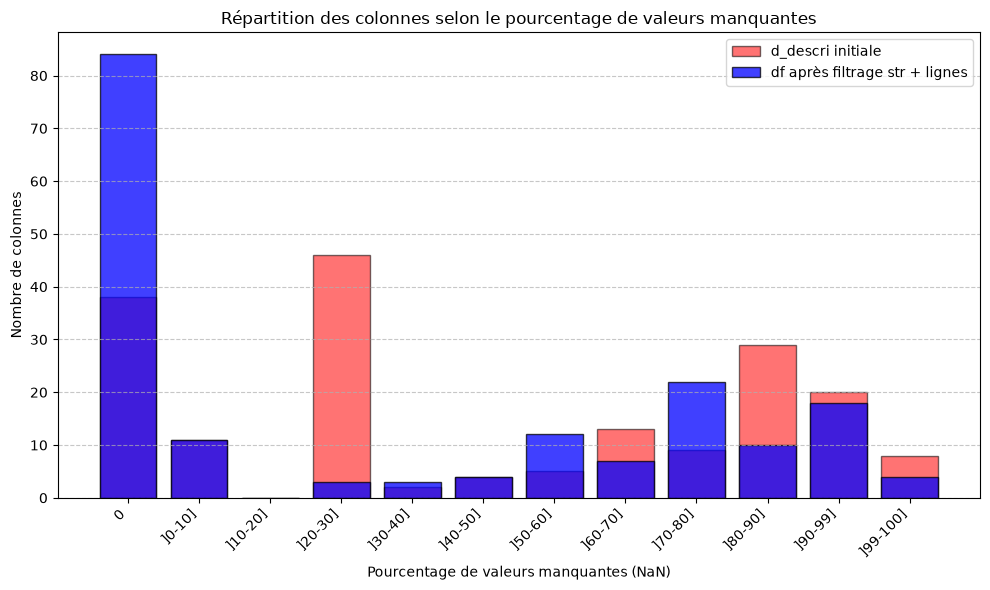

In [11]:
# Pourcentage de valeurs manquantes dans les deux tables
nan_descri = d_descri.isna().mean() * 100
nan_df = df.isna().mean() * 100

bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
labels = [
    '0', ']0-10]', ']10-20]', ']20-30]', ']30-40]', ']40-50]',
    ']50-60]', ']60-70]', ']70-80]', ']80-90]', ']90-99]', ']99-100]'
]

counts_descri = pd.cut(
    nan_descri, bins=bins, labels=labels
).value_counts(sort=False)

counts_df = pd.cut(
    nan_df, bins=bins, labels=labels
).value_counts(sort=False)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))

# Table d_descri en arrière-plan
plt.bar(
    x, counts_descri.values,
    color='red', alpha=0.55,
    edgecolor='black', label='d_descri initiale'
)

# Table df au premier plan
plt.bar(
    x, counts_df.values,
    color='blue', alpha=0.75,
    edgecolor='black', label='df après filtrage str + lignes'
)

plt.title("Répartition des colonnes selon le pourcentage de valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes (NaN)")
plt.ylabel("Nombre de colonnes")
plt.xticks(x, labels, rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()

# plt.savefig("graphs/nan_distribution_comparaison.png")
plt.show()

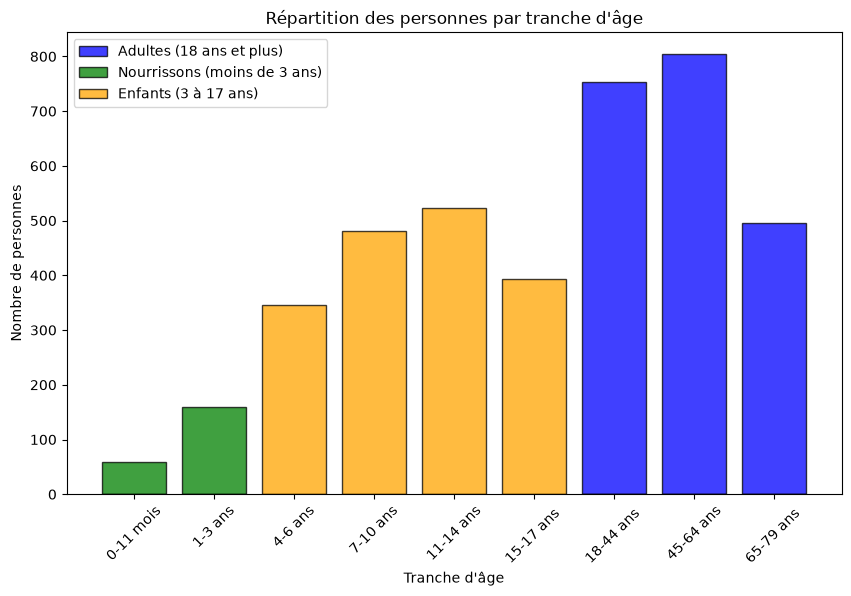

In [12]:
df_adulte = df[df["tage_PS"] >= 7]
df_nourisson = df[df["tage_PS"] < 3]
df_enfant = df[(df["tage_PS"] >= 3) & (df["tage_PS"] < 7)]

bins = [0,1,2,3,4,5,6,7,8,9]
labels = ['0-11 mois', '1-3 ans', '4-6 ans', '7-10 ans', '11-14 ans', '15-17 ans ', '18-44 ans ', '45-64 ans', '65-79 ans ']

counts_adulte = pd.cut(df_adulte["tage_PS"], bins=bins, labels=labels)
counts_nourisson = pd.cut(df_nourisson["tage_PS"], bins=bins, labels=labels)
counts_enfant = pd.cut(df_enfant["tage_PS"], bins=bins, labels=labels)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))
plt.bar(x, counts_adulte.value_counts(sort=False), color='blue', alpha=0.75, edgecolor='black', label='Adultes (18 ans et plus)')
plt.bar(x, counts_nourisson.value_counts(sort=False), color='green', alpha=0.75, edgecolor='black', label='Nourrissons (moins de 3 ans)')
plt.bar(x, counts_enfant.value_counts(sort=False), color='orange', alpha=0.75, edgecolor='black', label='Enfants (3 à 17 ans)')
plt.xlabel('Tranche d\'âge')
plt.ylabel('Nombre de personnes')
plt.title('Répartition des personnes par tranche d\'âge')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()


**Regler le problèmes des valeurs manquantes :**  
- Colonnes vides = suppression
- très peu de valeurs manquantes (<1% par exemple) = suppresion ligne
- bcp valeur manquantes : verification si c'est pas juste un 0 non encodé, ou resoudre le prbl. Si pas possible = ecarter la colonne
- Valeurs manquantes = "Non applicable" : la valeur manquante ne signifie pas un oublie ou un non, par exemple si on a repondu être un homme, il est logique qu'il n'y ai rien dans enceinte, répondre "non" est une information innatendue. Il faut imputer "non applicable"

In [ ]:
dfs = {
    "Adultes": df_adulte,
    "Enfants": df_enfant,
    "Nourrissons": df_nourisson
}

for nom, data in dfs.items():
    # 1. Supprimer les colonnes vides
    colonnes_vides = data.columns[data.isna().all()]
    data.drop(columns=colonnes_vides, inplace=True)

    # 2. Afficher les informations sur les colonnes restantes
    print(f"--- {nom} ---")
    print(f"{nom} : {len(colonnes_vides)} colonne(s) vide supprimée(s)")
    for k in data.columns:
        if data[k].isna().sum() > 0:
            print(
                f"Colonne '{k}' : "
                f"{data[k].nunique()} valeurs uniques, "
                f"{data[k].isna().sum()/len(data)*100:.2f}% de valeurs manquantes"
            )
    print('\n')



# Pourcentage de valeurs manquantes par colonne
bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
labels = [
    "0", "]0-10]", "]10-20]", "]20-30]", "]30-40]", "]40-50]",
    "]50-60]", "]60-70]", "]70-80]", "]80-90]", "]90-99]", "]99-100]"
]

comptages = {}

for nom, data in dfs.items():
    pourcentage_nan = data.isna().mean() * 100
    classes_nan = pd.cut(
        pourcentage_nan,
        bins=bins,
        labels=labels,
        include_lowest=True
    )
    comptages[nom] = classes_nan.value_counts(sort=False)

x = np.arange(len(labels))
largeur = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - largeur, comptages["Adultes"],
    width=largeur, color="blue", alpha=0.75, label="Adultes"
)
plt.bar(
    x, comptages["Enfants"],
    width=largeur, color="orange", alpha=0.75, label="Enfants"
)
plt.bar(
    x + largeur, comptages["Nourrissons"],
    width=largeur, color="green", alpha=0.75, label="Nourrissons"
)

plt.title("Nombre de colonnes selon leur pourcentage de valeurs manquantes")
plt.xlabel("Pourcentage de valeurs manquantes")
plt.ylabel("Nombre de colonnes")
plt.xticks(x, labels, rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

### Colonnes ou on remplace nan par 0 :
1. Le tabagisme : six quantités  

|format_fume|signification|  
|---|---|  
|1|Oui, quotidiennement|  
|2|Oui, occasionnellement|  
|3|Non, mais a déjà fumé|  
|4|Non, jamais fumé|  

- donc si `fume` vaut 3 ou 4, on peut logiquement mettre 0 dans `nb_cigarettes_jour`, `nb_cigarettes_sem`, `nb_cigarettes_nsp `, `nb_cigares_jour`, `nb_cigares_sem`,  `nb_cigares_nsp`, `nb_pipes_jour`, `nb_pipes_sem`, `nb_pipes_nsp`
- Si `fume` vaut 4, on peut mettre $non applicable$ dans `fume_age_debut`, `ume_age_debut_nsp`, `fume_age_arret`, `fume_age_arret_nsp`
- Si `fume` vaut 1 ou 2, et qu'on a :
  - si `nb_*_nsp` == 1, on met $NaN$ ou 200 dans les 6 autres catégories (`*_jour` et `*_sem`)
  - si `nb_*_jour` == nan et `nb_*_sem` == x, on peut `nb_*_jour` = x / 7 (on aura pas des entier)
  - si `nb_*_sem` == nan et `nb_*_jour` == x, on peut `nb_*_sem` = x * 7 (on aura pas des entier)
  - si on a un chiffre dans cigarette, cigares ou pipe mais pas les autres, on met 0 dans les autres catégories

In [72]:
colonnes_fume = ["NOIND", "fume", "nb_cigarettes_jour", "nb_cigarettes_sem", "nb_cigarettes_nsp", "nb_cigares_jour", "nb_cigares_sem", "nb_cigares_nsp", "nb_pipes_jour", "nb_pipes_sem", "nb_pipes_nsp", "fume_age_debut", "fume_age_debut_nsp", "fume_age_arret", "fume_age_arret_nsp"]

d_fume = df.loc[:, colonnes_fume].copy()

colonnes_nb = [col for col in d_fume.columns if col.startswith("nb_")]
colonnes_age = [col for col in d_fume.columns if col.startswith("fume_age_")]

''' Pour trouver 2 individus qui posaient problèmes
autres_colonnes_fume = [col for col in colonnes_fume if col != "NOIND"]

masque = (
    df["fume"].isna()
    & df[autres_colonnes_fume].notna().any(axis=1)
)

print(df.loc[masque, colonnes_fume])

'''

idx = {
    k: d_fume.index[d_fume["fume"].eq(k)].to_numpy()
    for k in range(1, 5)
}

groupes = {
    "cigarettes": ["nb_cigarettes_jour", "nb_cigarettes_sem", "nb_cigarettes_nsp"],
    "cigares": ["nb_cigares_jour", "nb_cigares_sem", "nb_cigares_nsp"],
    "pipes": ["nb_pipes_jour", "nb_pipes_sem", "nb_pipes_nsp"],
}

# Si jamais fumé (fume = 3)
indices = idx[3]
d_fume.loc[indices, colonnes_nb] = 0

# Si n'a jamais fumé (fume = 4)
indices = idx[4]
d_fume.loc[indices, colonnes_nb] = 0
d_fume.loc[indices, colonnes_age] = np.nan

# Si a fumé par le passé (fume = 2)
indices = idx[2]
d_fume.loc[indices, colonnes_nb] = 0

# Si fume actuellement (fume = 1 ou 2)
for groupe, colonnes in groupes.items():
    jour, sem, nsp = colonnes

    # Si la quantité est non spécifiée, les quantités jour et semaine
    # ne peuvent pas être déterminées
    mask_nsp = d_fume["fume"].isin([1, 2]) & d_fume[nsp].eq(1)
    d_fume.loc[mask_nsp, [jour, sem]] = np.nan

    # Conversion entre quantités journalières et hebdomadaires
    mask_jour = (
        d_fume["fume"].isin([1, 2])
        & d_fume[jour].isna()
        & d_fume[sem].notna()
        & d_fume[nsp].ne(1)
    )
    d_fume.loc[mask_jour, jour] = d_fume.loc[mask_jour, sem] / 7

    mask_sem = (
        d_fume["fume"].isin([1, 2])
        & d_fume[sem].isna()
        & d_fume[jour].notna()
        & d_fume[nsp].ne(1)
    )
    d_fume.loc[mask_sem, sem] = d_fume.loc[mask_sem, jour] * 7

# Si une catégorie de tabac est consommée, les autres catégories
# sont mises à 0 uniquement si leurs quantités sont toutes manquantes
for groupe_source, colonnes_source in groupes.items():
    masque_source = (
        d_fume["fume"].isin([1, 2])
        & d_fume[colonnes_source[:2]].fillna(0).gt(0).any(axis=1)
    )

    for groupe_cible, colonnes_cible in groupes.items():
        if groupe_cible == groupe_source:
            continue

        masque_cible = d_fume[colonnes_cible].isna().all(axis=1)
        masque = masque_source & masque_cible
        d_fume.loc[masque, colonnes_cible] = 0

comparaison_na = pd.DataFrame({
    "NaN_avant_df": df[colonnes_fume].isna().sum(),
    "NaN_apres_d_fume": d_fume[colonnes_fume].isna().sum()
})

comparaison_na["difference_NaN"] = (
    comparaison_na["NaN_apres_d_fume"] - comparaison_na["NaN_avant_df"]
)

comparaison_na



,NaN_avant_df,NaN_apres_d_fume,difference_NaN
NOIND,0,0,0
fume,1079,1079,0
nb_cigarettes_jour,3098,1087,-2011
nb_cigarettes_sem,3874,1087,-2787
nb_cigarettes_nsp,3931,1548,-2383
nb_cigares_jour,3049,1098,-1951
nb_cigares_sem,3918,1100,-2818
nb_cigares_nsp,3939,1535,-2404
nb_pipes_jour,3075,1099,-1976
nb_pipes_sem,3930,1101,-2829


2. Historique des régimes amaigrissants

|regime_passe|signification|  
|---|---|  
|1|Oui|  
|2|Non|  
|3|Ne sait pas|  
|4|Refus|  

- si `regime_passe` == 2, on peut mettre 0/$non-applicable$ dans `regime_nb_2dernann`, `regime_nb_anter2dernann `, `regime_nb_anter2dernann  `, `regime_duree_sem`, `regime_duree_mois`, `regime_duree_nsp`
- transformer toutes les `regime_duree_mois` en `regime_duree_sem`, ou faire *4 /4 pour remplir les cases vides si possible

In [ ]:
###TODO###

regime_passe
NaN    1350
2.0     358
1.0      30
3.0       4
Name: count, dtype: int64

In [ ]:
# compte chaque valeur unique, y compris les NaN
df_enfant['regime_passe'].value_counts(dropna=False)